# Orion over Mt. San Miguel East

Mt. San Miguel's east-facing site carries two cameras side by side: a colour unit
(`sm-e-mobo-c`) and a monochrome one (`sm-e-mobo-m`). Both are listed at a heading of 90°
with no tilt or roll. This notebook solves both from the same 90 minutes, 00:00–01:30 local
time on 7 October 2026, while Orion, Gemini and Taurus rise in the east. It then checks the
solve three ways that a reader can see at a glance:

- **Constellations.** Stick figures drawn through the solved pose on a night frame, next to
  the same figures drawn through the published pose.
- **Terrain ridges.** Crests from a terrain model drawn on an afternoon frame from the same
  day, through each pose.
- **Other nights.** The pose from 7 October drawn on frames from 3 and 25 nights earlier,
  and a pose from 25 nights earlier drawn on 7 October. Nothing is fitted on the night it
  is drawn on.

The steps are the ones `hpwren_worked_example.ipynb` explains in detail, with one
difference: the sky is tracked twice. The first pass lets bigger blobs count as stars, so
the brightest ones (Betelgeuse, Rigel, Capella) take part, and it finds the pose. Through
that pose, a terrain model gives the skyline, and the second pass looks for stars of the
usual size everywhere above it, instead of only in the top 35% of the frame. Bright stars
saturate, so their centres are less sharp; the second pass's pose is the one used from then
on. This notebook runs the steps without the commentary.

**Data:** camera frames from [HPWREN](https://www.hpwren.ucsd.edu/), from its public CDN.
Terrain: Copernicus DEM GLO-30 (see `terrain.py`).

**To run it:** as for the worked example, from the `examples/` directory so that
`terrain.py` can be imported. It needs the `detect` argument to `tracks.collect`, which is
not yet in a release. It downloads about 150 MB of frames and, if the other examples
haven't already, about 150 MB of terrain tiles. The CDN keeps about the last 89 days of
frames, so the dates below expire in early December 2026.

In [1]:
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree

import terrain   # examples/terrain.py
from star_calibration import catalog, overlay
from star_calibration.intrinsics import lookup
from star_calibration.solve import Night, solve_wide
from star_calibration.tracks import clean, collect, detect_points
from star_calibration.hpwren import cache_dir, cameras, intrinsics_path, nights

CAMS = ["sm-e-mobo-c", "sm-e-mobo-m"]
DAY = "20261007"        # the night: Q1 is 00:00-02:59 local time; we use the first 90 min
DAY_TIME = "20261007"   # an afternoon block (Q6, 15:00 local): the sun is behind these cameras
OTHER_NIGHTS = {"20261004": "3 nights earlier", "20260912": "25 nights earlier"}   # both clear
BIG = {False: (1, 80), True: (2, 120)}   # first-pass blob sizes in px: colour, monochrome


def show(img_bgr, title=None, width=14):
    h, w = img_bgr.shape[:2]
    plt.figure(figsize=(width, width * h / w))
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    if title:
        plt.title(title, loc="left")
    plt.show()


def read_block(cam, day, q):
    d = cache_dir() / "nights" / cam / f"{day}_Q{q}"
    paths = sorted(d.glob("*.jpg"), key=lambda p: int(p.stem))   # files are named by epoch
    epochs = [int(p.stem) for p in paths]
    t0 = epochs[len(epochs) // 2]
    return t0, [(e, e - t0, p.read_bytes()) for e, p in zip(epochs, paths)]

## 1. Solve both cameras

Fetch, track, clean and solve, as in the worked example, but in the two passes described
above. `collect` hands its `detect` argument to the star detector: the blob sizes in the
first pass, the mask of the sky in the second. The monochrome camera's stars are fainter
and denser, so `collect` uses its monochrome detector and a linker that predicts each
star's next position. Each camera's optical centre comes from `intrinsics.json`, fitted
from all of its nights.

In [2]:
intr = json.loads(intrinsics_path().read_text())


def solve_block(name, day, keep_frames=True):
    """Fetch one camera's first 90 minutes of `day`, track and solve it in two passes."""
    print(nights.fetch(name, day, q=1, n_frames=90))
    cam = cameras()[name]
    t0, frames = read_block(name, day, 1)
    mono = cam["imager"] == "monochrome"   # the monochrome units have their own detector and linker

    def track(detect, keep):
        linked, decoded = collect(frames, lat=cam["lat"], lon=cam["lon"], mono=mono,
                                  max_gap_s=240 if mono else 300, detect=detect, keep_frames=keep)
        tracks, counts = clean(linked, banner_px=60)
        return tracks, counts, decoded

    # Pass 1: bigger blobs, so the brightest stars count. Only the pose is kept.
    tracks, _, decoded = track({"area_range": BIG[mono]}, False)
    H, W = next(iter(decoded.values()))[1].shape[:2]
    cx, cy = lookup(intr, name, W, H, t0)
    cam_c = {**cam, "cx": cx, "cy": cy}
    first = solve_wide(Night(camera=name, cam=cam_c, t0=t0, tracks=tracks, W=W, H=H))

    # Pass 2: stars of the usual size, anywhere above the skyline as seen through that pose.
    mask = terrain.sky_mask(cam_c, first["pose"], W, H, terrain.skyline(cam))
    tracks, counts, decoded = track({"sky_mask": mask}, keep_frames)
    night = Night(camera=name, cam=cam_c, t0=t0, tracks=tracks, W=W, H=H, label=f"{name} {day} Q1")
    r = solve_wide(night)
    print(f"  {counts}")
    return dict(cam=cam, cam_c=cam_c, night=night, decoded=decoded, r=r, first=first, mask=mask,
                W=W, H=H, t0=t0)


solved = {name: solve_block(name, DAY) for name in CAMS}

print()
for name, s in solved.items():
    r, p, f = s["r"], s["r"]["pose"], s["first"]
    print(f"{name}: pass 1 {f['n_stars']} stars, median {f['median_px']:.2f} px; "
          f"pass 2 {r['status']}, {r['n_stars']} stars, median {r['median_px']:.2f} px, "
          f"centre ({s['cam_c']['cx']}, {s['cam_c']['cy']}) px")
    print(f"  d_az {p['d_az']:+.2f}  d_pitch {p['d_pitch']:+.2f}  d_roll {p['d_roll']:+.2f} deg   "
          f"lens {p['k_ratio']:.4f}x, k1 {p['k1']:+.4f}")
    print(f"  heading {(s['cam']['az'] + p['d_az']) % 360:.2f} deg against the table's {s['cam']['az']}")

('sm-e-mobo-c', '20261007', 90, 90)


frames: 90/90 frames dark enough (sun el <= -8.0)


  776 raw tracks -> 54 moving, persistent tracks


downloading Copernicus_DSM_COG_10_N31_00_W118_00_DEM


frames: 90/90 frames dark enough (sun el <= -8.0)


...

frames: 90/90 frames dark enough (sun el <= -8.0)


  1940 raw tracks -> 445 moving, persistent tracks


frames: 90/90 frames dark enough (sun el <= -8.0)


  2730 raw tracks -> 467 moving, persistent tracks


  {'linked': 467, 'wandering': 0, 'split': 3, 'banner': 0, 'duplicate': 0, 'kept': 467}

sm-e-mobo-c: pass 1 41 stars, median 0.47 px; pass 2 solved, 30 stars, median 0.56 px, centre (-20.7, -25.4) px
  d_az -3.52  d_pitch +1.82  d_roll -0.86 deg   lens 0.8847x, k1 -0.0756
  heading 86.48 deg against the table's 90
sm-e-mobo-m: pass 1 29 stars, median 0.56 px; pass 2 solved, 40 stars, median 0.63 px, centre (18.2, -19.0) px
  d_az -3.64  d_pitch +1.98  d_roll -0.81 deg   lens 0.8863x, k1 -0.0778
  heading 86.36 deg against the table's 90


The second pass's search region on the colour camera: everything above the terrain
skyline, as the first pass's pose places it, and half a degree clear of it for the trees
and masts the terrain model doesn't have. Red marks what is left out. The dashed line is
where the usual search stops, 35% of the way down. The masts and the beacon are inside the
region, but they don't move with the sky, so they never become tracks.

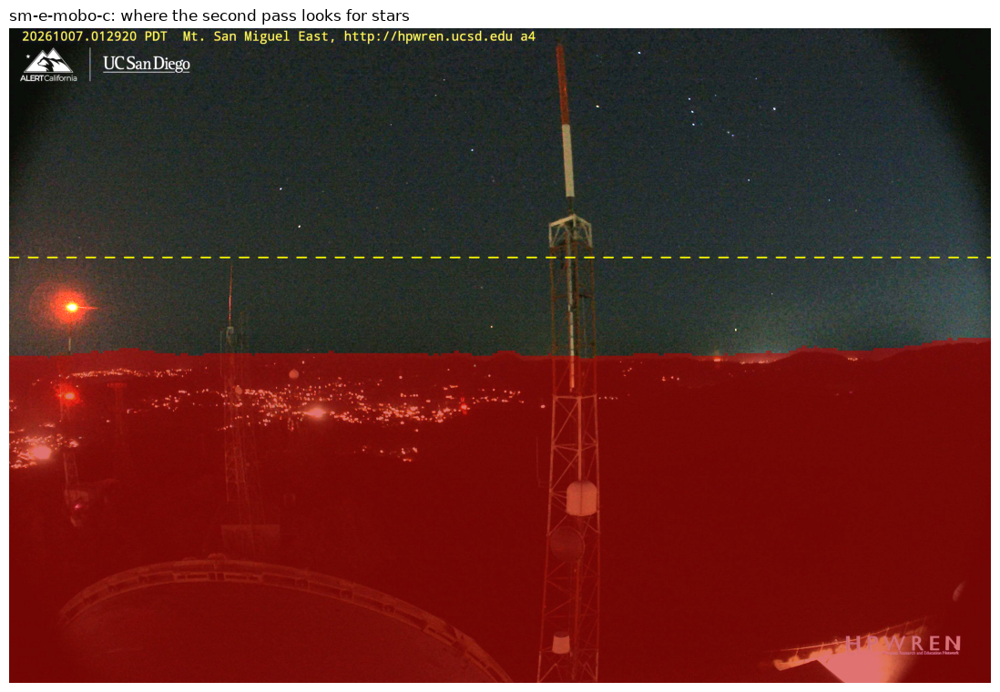

In [3]:
s = solved["sm-e-mobo-c"]
img = cv2.convertScaleAbs(s["decoded"][max(s["decoded"])][1], alpha=2.5, beta=10)
out = ~s["mask"]
img[out] = (img[out] * 0.45 + np.array([0, 0, 110])).astype(np.uint8)
y35 = int(0.35 * s["H"])
for x in range(0, s["W"], 60):
    cv2.line(img, (x, y35), (x + 30, y35), (0, 255, 255), 4)
show(img, "sm-e-mobo-c: where the second pass looks for stars")

Both passes find the same pose to about 0.01°. On these two cameras the published-pose
solve was already good, so what the passes add is stars: the usual detector, small blobs
in the top 35% only, matches 25 on each camera. Both cameras come out turned about 3.5°
left of 90°, tilted about 2° up, and rolled almost 1°. They sit side by side on one mount,
so they should agree, and they do: the headings differ by about 0.1°.

## 2. The solve on its own frames

Matched tracks are thick green, with each star's predicted arc under the fitted pose in
thin magenta inside it. Orange shows the same stars under the published pose, and yellow
arrows run from where the published pose puts each star to where the fit has it.

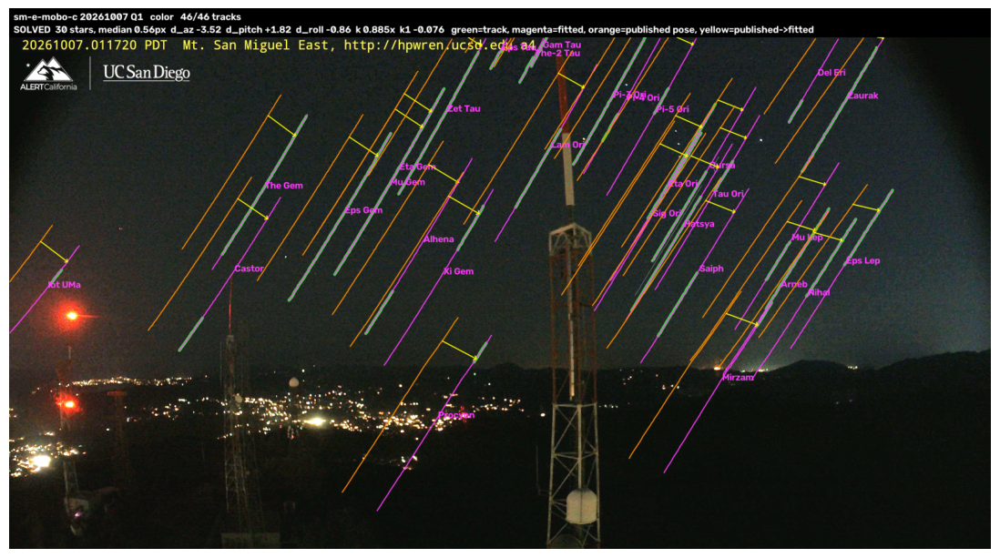

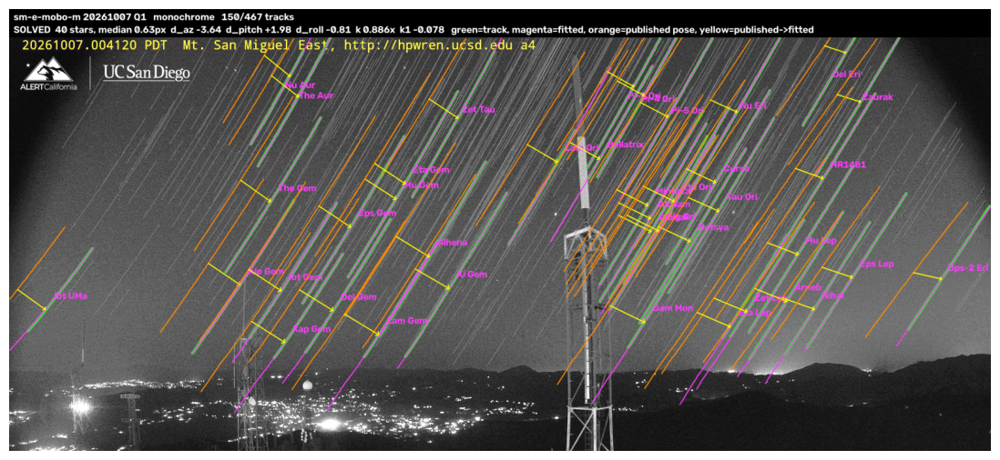

In [4]:
for name, s in solved.items():
    ref = overlay.reference_offset(s["r"], s["night"])
    nearest = min(s["decoded"], key=lambda o: abs(o - ref))
    show(overlay.draw(s["r"], s["night"], s["decoded"][nearest][1]))

## 3. Constellations

The stick figures below join catalog stars at the frame's time and project them through a
pose. Solid cyan uses the solved pose, lens and optical centre. Dashed orange uses the
published pose with the shared lens and the frame's middle as the centre: what the camera
table alone would predict. Nothing here is fitted to the picture. The frame is the last of
the block, at about 01:29, when Orion stands highest.

Only stars down to magnitude 4 are in the catalog, so the figures use those.

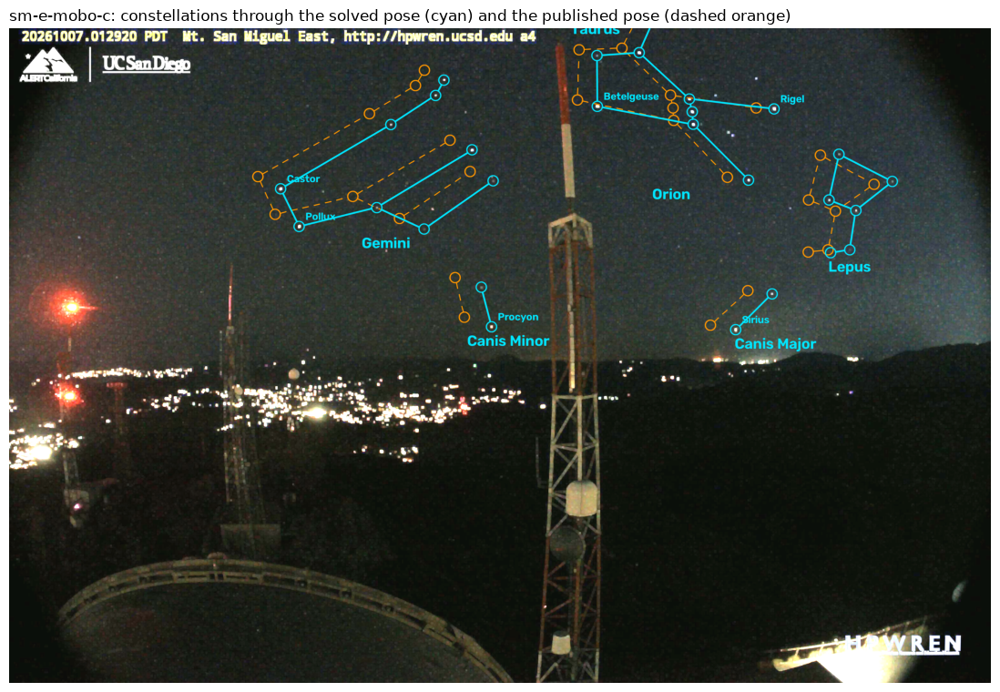

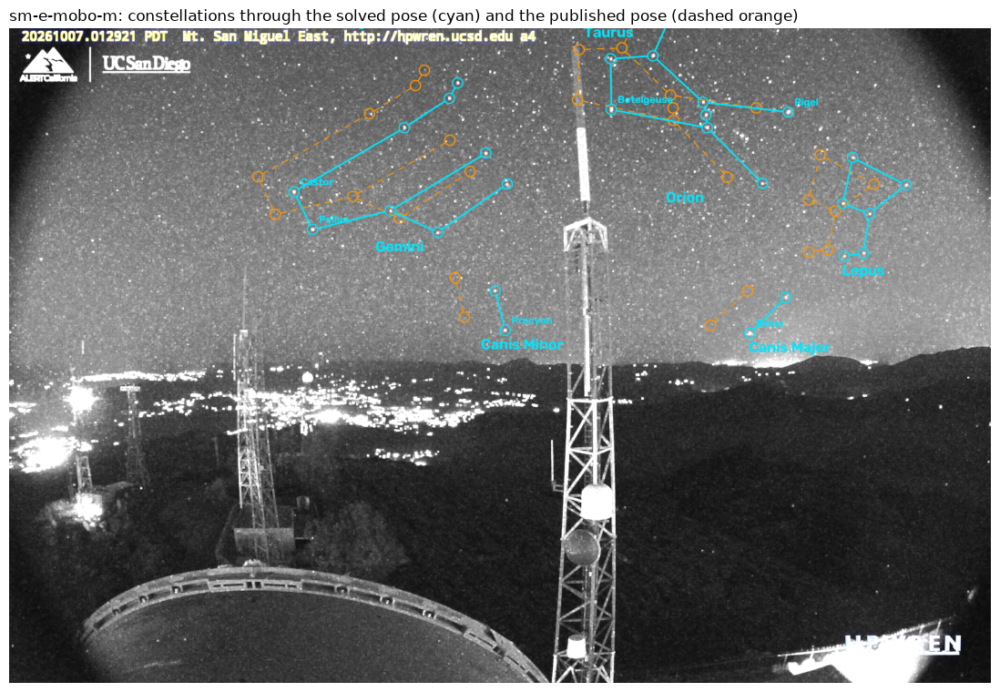

In [5]:
FIGURES = {
    "Orion": [["Betelgeuse", "Lam Ori", "Bellatrix"], ["Betelgeuse", "Alnitak", "Saiph"],
              ["Bellatrix", "Mintaka", "Rigel"], ["Mintaka", "Alnilam", "Alnitak"],
              ["Bellatrix", "Pi-3 Ori"], ["Pi-5 Ori", "Pi-4 Ori", "Pi-3 Ori"]],
    "Taurus": [["Alnath", "Eps Tau", "Del-1 Tau", "Gam Tau", "The-2 Tau", "Aldebaran", "Zet Tau"],
               ["Gam Tau", "Lam Tau", "Omi Tau"]],
    "Gemini": [["Castor", "Pollux"], ["Castor", "Eps Gem", "Mu Gem", "Eta Gem"],
               ["Pollux", "Del Gem", "Lam Gem", "Xi Gem"], ["Del Gem", "Alhena"]],
    "Auriga": [["Capella", "Menkalinan", "The Aur", "Alnath", "Hassaleh", "Capella"]],
    "Canis Minor": [["Procyon", "Gomeisa"]],
    "Canis Major": [["Mirzam", "Sirius", "Omi-2 CMa", "Wezen", "Adhara"], ["Wezen", "Aludra"]],
    "Lepus": [["Arneb", "Mu Lep", "Eps Lep", "Nihal", "Arneb"], ["Nihal", "Gam Lep", "Del Lep"]],
}
LABELS = {"Betelgeuse", "Rigel", "Aldebaran", "Castor", "Pollux", "Capella", "Procyon", "Sirius"}
PLEIADES = "Alcyone"


def figure_pixels(s, epoch, pose):
    # Each figure star's pixel through one pose: the solved one, or (pose=None) the published one.
    cam = s["cam_c"] if pose else s["cam"]
    names = sorted({n for segs in FIGURES.values() for seg in segs for n in seg} | {PLEIADES})
    alt_az = [catalog.star_altaz(n, epoch, cam["lat"], cam["lon"], cam["elev"]) for n in names]
    alt, az = np.array([a for a, _ in alt_az]), np.array([z for _, z in alt_az])
    x, y = terrain.project(cam, az, alt, s["W"], s["H"], pose)
    return {n: (float(xi), float(yi)) for n, xi, yi, a in zip(names, x, y, alt)
            if np.isfinite(xi) and np.isfinite(yi) and a > -2}


R_STAR = 16   # px: the ring round each star; lines stop at it so the star stays visible


def segment(img, p, q, colour, width, solid, dash=18):
    p, q = np.array(p), np.array(q)
    d = np.linalg.norm(q - p)
    if d <= 2 * R_STAR:
        return
    p, q = p + (q - p) * R_STAR / d, q - (q - p) * R_STAR / d
    n = 1 if solid else max(1, int((d - 2 * R_STAR) / dash))
    for i in range(0, n, 1 if solid else 2):
        a, b = p + (q - p) * i / n, p + (q - p) * min(i + 1, n) / n
        cv2.line(img, tuple(int(v) for v in a), tuple(int(v) for v in b), colour, width, cv2.LINE_AA)


def draw_figures(img, pix, colour, width, solid=True, labels=True):
    for con, segs in FIGURES.items():
        placed = []
        for seg in segs:
            for a, b in zip(seg[:-1], seg[1:]):
                if a in pix and b in pix:
                    segment(img, pix[a], pix[b], colour, width, solid)
            placed += [pix[n] for n in seg if n in pix]
        for n in {n for seg in segs for n in seg} & set(pix):
            cv2.circle(img, tuple(int(v) for v in pix[n]), R_STAR, colour, 2, cv2.LINE_AA)
        if labels and placed:
            x, y = np.mean([p[0] for p in placed]), max(p[1] for p in placed) + 60
            cv2.putText(img, con, (int(x) - 60, int(y)), cv2.FONT_HERSHEY_SIMPLEX, 1.6, colour, 4, cv2.LINE_AA)
    if labels:
        for n in LABELS & set(pix):
            cv2.putText(img, n, (int(pix[n][0]) + 20, int(pix[n][1]) - 20),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.1, colour, 3, cv2.LINE_AA)
        if PLEIADES in pix:
            cv2.circle(img, tuple(int(v) for v in pix[PLEIADES]), 40, colour, 3, cv2.LINE_AA)
            cv2.putText(img, "Pleiades", (int(pix[PLEIADES][0]) + 46, int(pix[PLEIADES][1])),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.4, colour, 3, cv2.LINE_AA)


def night_canvas(frame, gain):
    # Brightened, with each star swollen to 5 px so it survives the notebook's downscaling.
    return cv2.dilate(cv2.convertScaleAbs(frame, alpha=gain, beta=10), np.ones((5, 5), np.uint8))


CYAN, ORANGE = (255, 230, 0), (0, 150, 255)
for name, s in solved.items():
    off = max(s["decoded"])
    epoch, frame = s["decoded"][off]
    img = night_canvas(frame, 2.5)
    draw_figures(img, figure_pixels(s, epoch, None), ORANGE, 2, solid=False, labels=False)
    draw_figures(img, figure_pixels(s, epoch, s["r"]["pose"]), CYAN, 3)
    show(img, f"{name}: constellations through the solved pose (cyan) and the published pose (dashed orange)")

The cyan figures sit on the stars. The orange ones are shifted left and twisted: the 3.5°
heading, 2° tilt and 1° roll the solve measured.

Up close, on Orion in the monochrome frame at full resolution. The fuzzy patch beside the
belt, on the side away from Betelgeuse, is the Orion Nebula in Orion's sword:

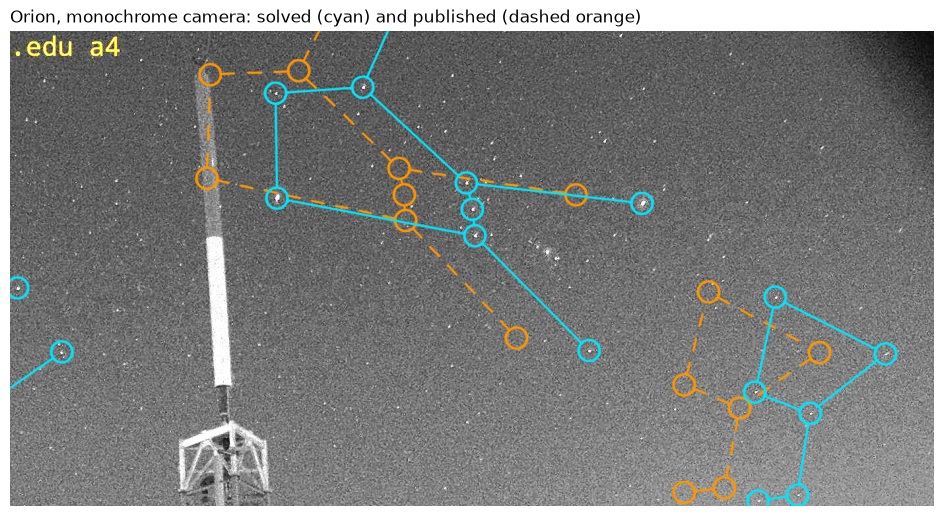

In [6]:
s = solved["sm-e-mobo-m"]
off = max(s["decoded"])
epoch, frame = s["decoded"][off]
img = cv2.convertScaleAbs(frame, alpha=3.0, beta=10)
pix = figure_pixels(s, epoch, s["r"]["pose"])
draw_figures(img, figure_pixels(s, epoch, None), ORANGE, 2, solid=False, labels=False)
draw_figures(img, pix, CYAN, 2, labels=False)
cx, cy = (int(v) for v in pix["Alnilam"])
crop = img[max(0, cy - 450):cy + 450, max(0, cx - 700):cx + 700]
show(crop, "Orion, monochrome camera: solved (cyan) and published (dashed orange)", width=12)

## 4. Terrain ridges

The constellations test the solve against the sky it was fitted to. Terrain tests it
against something else entirely. `terrain.crests` marches rays across each camera's view
through the Copernicus 30 m surface model and returns every crest: the last point before
the terrain behind it drops out of sight. The skyline is drawn yellow and the inner crests
magenta (solved pose) or orange (published pose). The frame is from 15:00 the same day,
when the sun is behind these east-facing cameras.

('sm-e-mobo-c', '20261007', 3, 3)


  16737 crest points, 2216 on the skyline


('sm-e-mobo-m', '20261007', 3, 3)


  16737 crest points, 2216 on the skyline


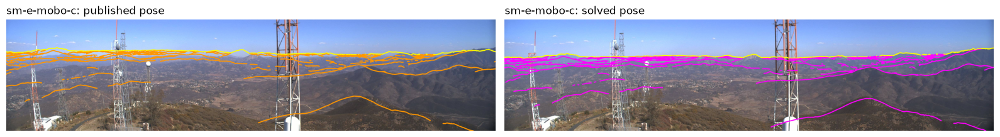

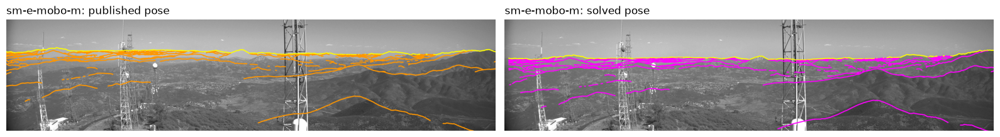

In [7]:
for name, s in solved.items():
    print(nights.fetch(name, DAY_TIME, q=6, n_frames=3))
    path = sorted((cache_dir() / "nights" / name / f"{DAY_TIME}_Q6").glob("*.jpg"))[0]
    s["day"] = cv2.imread(str(path))
    s["crests"] = terrain.crests(s["cam"], min_km=0.5)
    az, el, km, sky = s["crests"]
    print(f"  {len(az)} crest points, {sky.sum()} on the skyline")


def draw_crests(img, x, y, sky, colour, r=3):
    ok = np.isfinite(x) & np.isfinite(y)
    for xi, yi, si in zip(x[ok], y[ok], sky[ok]):
        cv2.circle(img, (int(xi), int(yi)), r, (0, 255, 255) if si else colour, -1)


MAGENTA = (255, 0, 255)
for name, s in solved.items():
    az, el, km, sky = s["crests"]
    views = {"published pose": (terrain.project(s["cam"], az, el, s["W"], s["H"]), ORANGE),
             "solved pose": (terrain.project(s["cam_c"], az, el, s["W"], s["H"], s["r"]["pose"]), MAGENTA)}
    s["views"] = views
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))
    for ax, (label, ((x, y), colour)) in zip(axes, views.items()):
        img = s["day"].copy()
        draw_crests(img, x, y, sky, colour)
        ax.imshow(cv2.cvtColor(img[800:1500], cv2.COLOR_BGR2RGB), extent=(0, s["W"], 1500, 800))
        ax.set_title(f"{name}: {label}", loc="left")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

Closer, at three places across the colour frame: the near ridge on the left, the peak in
the middle, and the hills on the right.

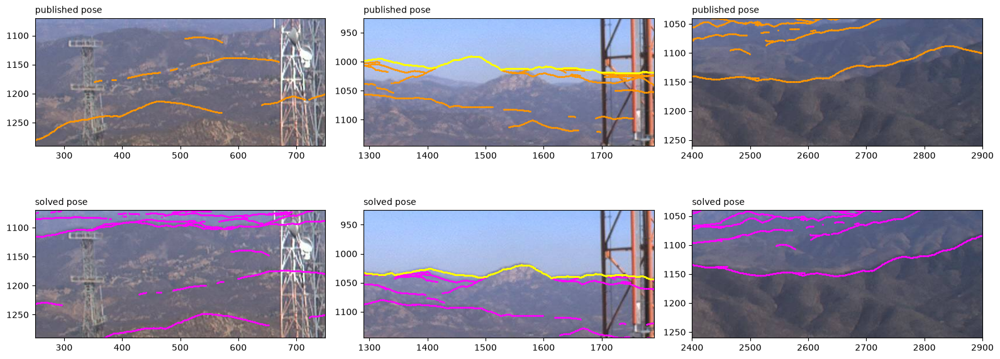

In [8]:
WINDOWS = [(500, 1180), (1540, 1035), (2650, 1150)]     # (x, y) centres in the colour frame
s = solved["sm-e-mobo-c"]
az, el, km, sky = s["crests"]
fig, axes = plt.subplots(2, len(WINDOWS), figsize=(16, 6.5))
for row, (label, ((x, y), colour)) in enumerate(s["views"].items()):
    for col, (x0, y0) in enumerate(WINDOWS):
        ax = axes[row, col]
        ax.imshow(cv2.cvtColor(s["day"], cv2.COLOR_BGR2RGB))
        m = (x > x0 - 250) & (x < x0 + 250)
        c = np.array(colour[::-1]) / 255
        ax.plot(x[m & ~sky], y[m & ~sky], ".", ms=2, color=c)
        ax.plot(x[m & sky], y[m & sky], ".", ms=2.5, color="yellow")
        ax.set_xlim(x0 - 250, x0 + 250)
        ax.set_ylim(y0 + 110, y0 - 110)
        ax.set_title(label, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

To put a number on it, score each pose by how strongly its crests sit on edges that are
bright above and dark below, then shift every crest up or down together and see where the
score peaks. A right pose peaks near zero. This mostly tests tilt and roll: ridges run
roughly level, so they hold the vertical tightly but say little about a small sideways
shift.

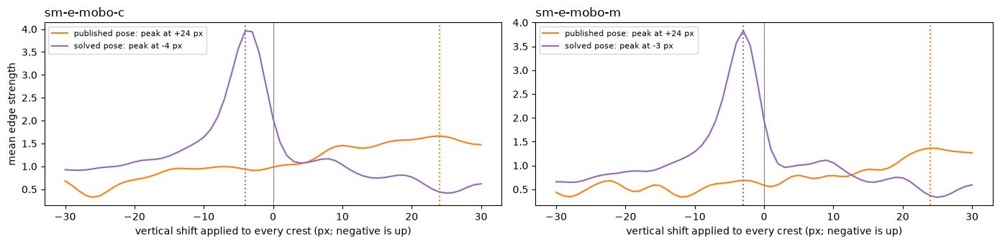

In [9]:
shifts = np.arange(-30, 31)
fig, axes = plt.subplots(1, len(solved), figsize=(14, 3.5), sharey=False)
for ax, (name, s) in zip(axes, solved.items()):
    edge = terrain.edge_map(s["day"])
    for (label, ((x, y), _)), colour in zip(s["views"].items(), ("tab:orange", "tab:purple")):
        sc = terrain.edge_score(edge, x, y, shifts)
        best = shifts[sc.argmax()]
        ax.plot(shifts, sc, color=colour, label=f"{label}: peak at {best:+d} px")
        ax.axvline(best, color=colour, ls=":")
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel("vertical shift applied to every crest (px; negative is up)")
    ax.set_title(name, loc="left")
    ax.legend(fontsize=8)
axes[0].set_ylabel("mean edge strength")
plt.tight_layout()
plt.show()

On both cameras the solved pose's score peaks sharply 3–4 px (about 0.1°) above zero:
its crests sit on the terrain's edges across the whole frame. The published pose's curve
has no clear peak at all. Its crests are off sideways by the 3.5° heading as well as
vertically by the 2° tilt, so no up-or-down shift alone lines them up.

## 5. The same pose on other nights

A pose belongs to the camera, not to the night. Unless the camera is bumped or re-aimed,
the pose solved on 7 October should put every star in the right place on any other night,
and the stars move on from night to night: each one rises about 4 minutes earlier every
day, so at the same clock time the whole sky has turned about 1° further west, 25° in 25
nights.

Below, the 7 October pose is drawn on two clear nights at the same time, 01:29: 4 October,
3 nights earlier, and 12 September, 25 nights earlier. The nights nearer a full month
before were cloudy or moonlit. Nothing is fitted on either night. On 12 September at 01:29,
Orion has only just cleared the hills, and Aldebaran stands as high as Betelgeuse does on
7 October.

('sm-e-mobo-c', '20261004', 90, 90)
('sm-e-mobo-c', '20260912', 90, 90)


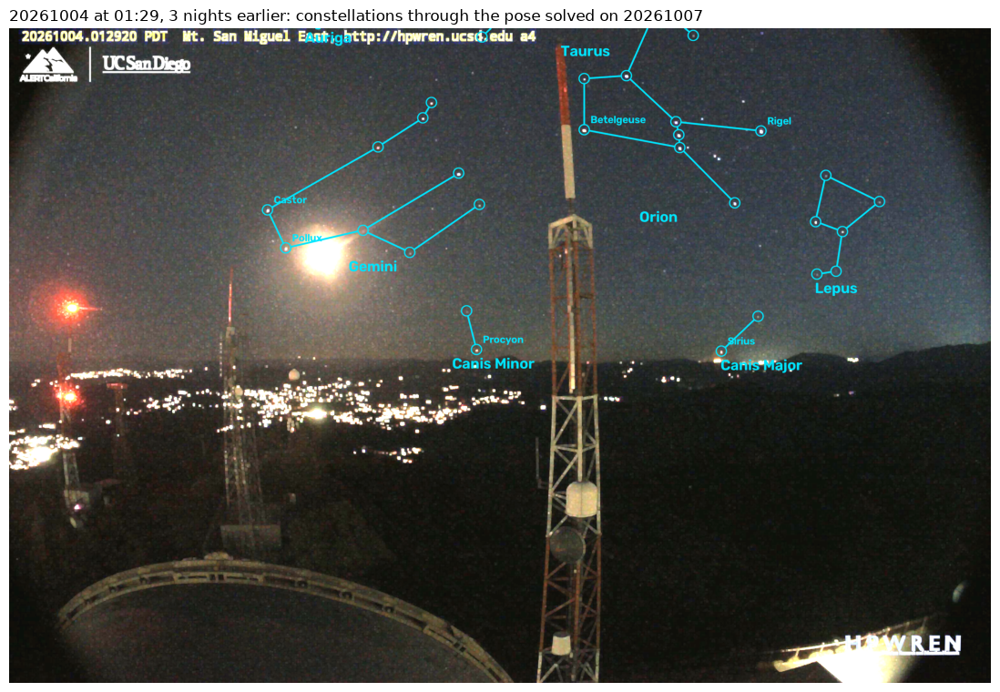

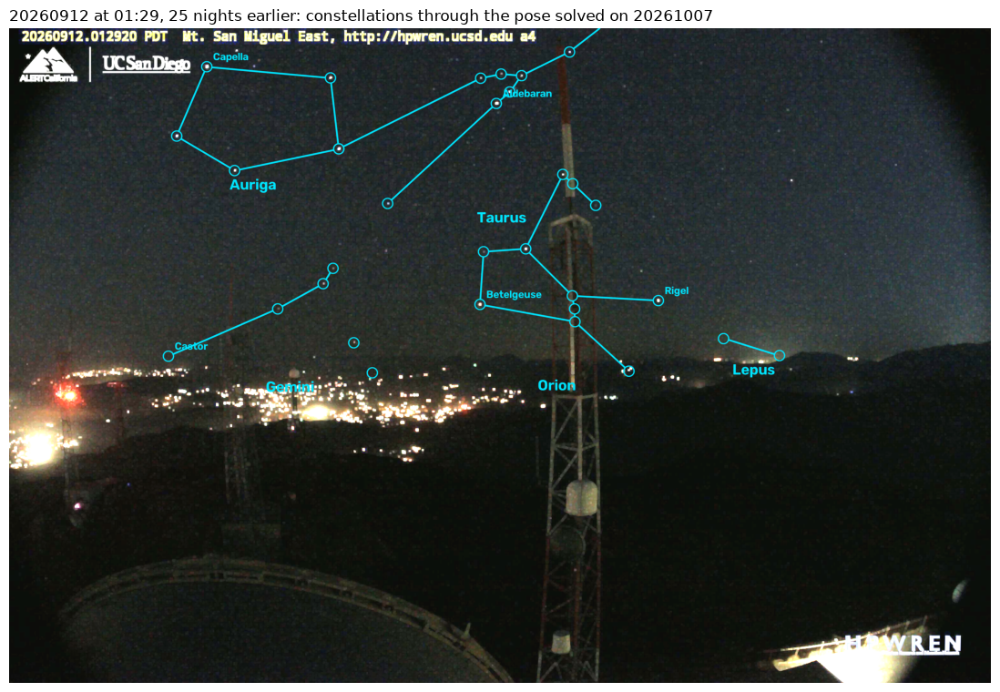

In [10]:
s = solved["sm-e-mobo-c"]
pose = s["r"]["pose"]
frames_at = {DAY: (s["t0"] + max(s["decoded"]), s["decoded"][max(s["decoded"])][1])}
for day in OTHER_NIGHTS:
    print(nights.fetch("sm-e-mobo-c", day, q=1, n_frames=90))
    _, frames = read_block("sm-e-mobo-c", day, 1)
    epoch, _, blob = frames[-1]                  # 01:29, the time of the frames above
    frames_at[day] = (epoch, cv2.imdecode(np.frombuffer(blob, np.uint8), cv2.IMREAD_COLOR))

for day, when in OTHER_NIGHTS.items():
    epoch, frame = frames_at[day]
    img = night_canvas(frame, 2.5)
    draw_figures(img, figure_pixels(s, epoch, pose), CYAN, 3)
    show(img, f"{day} at 01:29, {when}: constellations through the pose solved on {DAY}")

To put a number on it: take every catalog star brighter than magnitude 3.5 that the pose
puts in the sky region, and find the nearest point the star detector picks out of that one
frame. The detector knows nothing about the catalog or the pose. A star's image here is
3–5 px across, and a degree is about 34 px.

In [11]:
def offsets(frame, epoch, cam, pose, mask, mag_limit=3.5, radius=10):
    """Catalog stars predicted in the sky region, how many have a detection within `radius`
    px, and the median distance and (dx, dy) to it: detection minus prediction."""
    pts = np.array([p[:2] for p in detect_points(frame, sky_mask=mask)])
    stars = [r["name"] for r in catalog.CATALOG if r["mag"] <= mag_limit]
    alt_az = [catalog.star_altaz(n, epoch, cam["lat"], cam["lon"], cam["elev"]) for n in stars]
    alt, az = np.array([a for a, _ in alt_az]), np.array([z for _, z in alt_az])
    x, y = terrain.project(cam, az, alt, frame.shape[1], frame.shape[0], pose)
    H, W = mask.shape
    ok = np.isfinite(x) & np.isfinite(y) & (x >= 0) & (x < W) & (y >= 0) & (y < H)
    ok[ok] = mask[y[ok].astype(int), x[ok].astype(int)]
    d, j = cKDTree(pts).query(np.c_[x[ok], y[ok]], distance_upper_bound=radius)
    hit = np.isfinite(d)
    v = pts[j[hit]] - np.c_[x[ok], y[ok]][hit]
    return ok.sum(), hit.sum(), np.median(d[hit]), np.median(v, axis=0)


def report(label, day, pose_from):
    epoch, frame = frames_at[day]
    n, hits, med, (dx, dy) = offsets(frame, epoch, s["cam_c"], pose_from, s["mask"])
    print(f"{label:34s} {hits:2d} of {n:2d} stars found, median {med:.1f} px, "
          f"shift dx {dx:+.1f} dy {dy:+.1f} px")


report(f"{DAY}, the night solved", DAY, pose)
for day, when in OTHER_NIGHTS.items():
    report(f"{day}, {when}", day, pose)

20261007, the night solved         15 of 32 stars found, median 0.5 px, shift dx +0.2 dy -0.2 px


20261004, 3 nights earlier         12 of 34 stars found, median 2.3 px, shift dx +0.2 dy +2.3 px
20260912, 25 nights earlier        13 of 28 stars found, median 1.7 px, shift dx +0.7 dy -0.8 px


On the night it was solved, the pose puts the stars a median 0.5 px from where the
detector sees them. On 4 October, 3 nights away, it is 2.3 px, and on 12 September, 26
nights away, 1.7 px. Each night's misses lean one way: 2.3 px down on 4 October and 0.8 px
up on 12 September, about 0.07° and 0.02°. That is the camera itself tilting by a few
hundredths of a degree from night to night, perhaps as the mast warms and cools, and
solving either night on its own would take it up.

About half the predicted stars are found at all. The detector skips the brightest, whose
images are too big for it, and loses the faintest in the haze near the horizon. It is the
same half on every night, so the nights compare fairly.

## 6. A month ahead

The same test the other way round: solve 12 September on its own, with the same two
passes, and draw its pose on 7 October, 25 nights later. This is a prediction, made a month
in advance, of where every star in the frame will be.

('sm-e-mobo-c', '20260912', 90, 90)


frames: 90/90 frames dark enough (sun el <= -8.0)


  621 raw tracks -> 45 moving, persistent tracks


frames: 90/90 frames dark enough (sun el <= -8.0)


  1272 raw tracks -> 52 moving, persistent tracks


  {'linked': 52, 'wandering': 3, 'split': 9, 'banner': 0, 'duplicate': 0, 'kept': 51}
12 September: 36 stars, median 0.52 px


20261007, from the 20260912 pose   15 of 32 stars found, median 1.0 px, shift dx -0.5 dy +0.8 px


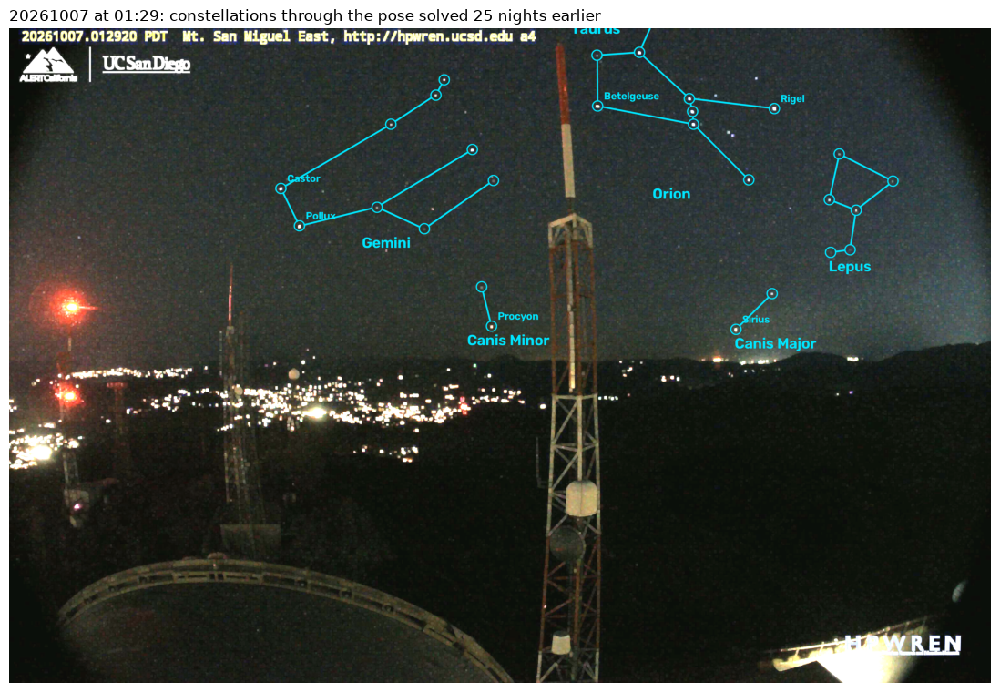

In [12]:
early = solve_block("sm-e-mobo-c", "20260912", keep_frames=False)
r = early["r"]
print(f"12 September: {r['n_stars']} stars, median {r['median_px']:.2f} px")
report(f"{DAY}, from the 20260912 pose", DAY, r["pose"])

epoch, frame = frames_at[DAY]
img = night_canvas(frame, 2.5)
draw_figures(img, figure_pixels(s, epoch, r["pose"]), CYAN, 3)
show(img, f"{DAY} at 01:29: constellations through the pose solved 25 nights earlier")

Up close, at full resolution: Orion and the foot of Taurus on each night, predicted from a
pose solved on a different night. Each panel follows Betelgeuse, wherever the sky has
carried it.

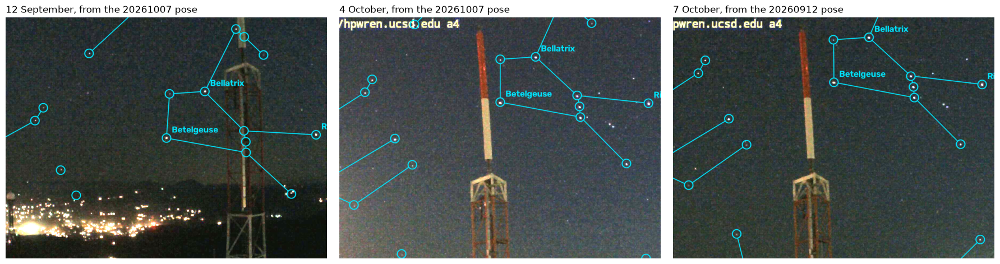

In [13]:
panels = [("20260912", pose, f"12 September, from the {DAY} pose"),
          ("20261004", pose, f"4 October, from the {DAY} pose"),
          (DAY, early["r"]["pose"], "7 October, from the 20260912 pose")]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, (day, p, title) in zip(axes, panels):
    epoch, frame = frames_at[day]
    img = cv2.dilate(cv2.convertScaleAbs(frame, alpha=3.0, beta=10), np.ones((3, 3), np.uint8))
    pix = figure_pixels(s, epoch, p)
    draw_figures(img, pix, CYAN, 2, labels=False)
    for n in ("Aldebaran", "Betelgeuse", "Rigel", "Bellatrix", "Alnath"):
        if n in pix:
            cv2.putText(img, n, (int(pix[n][0]) + 20, int(pix[n][1]) - 20),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.1, CYAN, 2, cv2.LINE_AA)
    cx, cy = (int(v) for v in pix["Betelgeuse"])
    x0 = min(max(0, cx - 600), s["W"] - 1200)     # a 1200 x 900 window, kept inside the frame
    y0 = min(max(0, cy - 450), s["H"] - 900)
    ax.imshow(cv2.cvtColor(img[y0:y0 + 900, x0:x0 + 1200], cv2.COLOR_BGR2RGB))
    ax.set_title(title, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.show()

Predicted 25 nights ahead, the stars land a median 1.0 px from where the detector finds
them, about 0.03°: less than a tenth of the Moon's width. In every panel the circles sit on
the stars, whichever night the pose came from. On this camera, one clear night's pose held
for at least the 25 nights between these two, to within the night-to-night tilt of a few
hundredths of a degree.

Camera frames: HPWREN, <https://www.hpwren.ucsd.edu/>. Terrain: Copernicus DEM GLO-30,
© DLR e.V. 2010–2014 and © Airbus Defence and Space GmbH 2014–2018, provided under
COPERNICUS by the European Union and ESA.